Importando bibliotecas


In [25]:
from pmdarima.arima import auto_arima

In [26]:
from pmdarima.arima import auto_arima

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


Carregando dataset

In [28]:
dataset = pd.read_csv("datasets/daily_forex_rates.csv",sep = ",",index_col = "date",parse_dates = True)

Retirando informações inciais do dataset


In [29]:
print(f"Dataset head (primeiras 5 linhas):\n{dataset.head()}")
print(f"Dataset shape (formato do dataset): {dataset.shape}")
print("Dataset info (informações do dataset):")
dataset.info()
print(f"Date range (menor e maior data): {dataset.index.min()} to {dataset.index.max()}")

print("Retirando dados nulos...")
dataset = dataset.dropna()

Dataset head (primeiras 5 linhas):
           currency base_currency     currency_name  exchange_rate
date                                                              
2026-11-13      MXV           EUR               NaN       2.310893
2026-11-13      GIP           EUR   Gibraltar Pound       0.835318
2026-11-13      HTG           EUR    Haitian Gourde     145.309584
2026-11-13      HRK           EUR     Croatian Kuna       7.533606
2026-11-13      HNL           EUR  Honduran Lempira      29.821219
Dataset shape (formato do dataset): (511661, 4)
Dataset info (informações do dataset):
<class 'pandas.DataFrame'>
DatetimeIndex: 511661 entries, 2026-11-13 to 2004-08-30
Data columns (total 4 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   currency       511661 non-null  str    
 1   base_currency  511661 non-null  str    
 2   currency_name  508540 non-null  str    
 3   exchange_rate  511661 non-null  float64
dtypes: float64(1), str(

Tratando dados para reunir informações que de fato será usado

In [30]:
filtrado = dataset[dataset["currency"].isin(["USD","BRL"])]
cambio = filtrado.pivot(columns="currency",values="exchange_rate")
cambio = cambio.rename(columns = {"USD" : "EUR_USD","BRL" : "EUR_BRL"})

print("Isolando colunas de interesse (relação euro com dólar e real) e pivotando(reorganizar,uma coluna por moeda, uma linha por data) o dataset...")
print(f"Dataset head (primeiras 5 linhas) após filtragem e pivotagem:\n{cambio.head()}")

print("Ordenando dataset por data e filtrando a partir de 28/10/2023...")
cambio = cambio.sort_index()
cambio = cambio.loc["2023-10-28":]
cambio.head()



Isolando colunas de interesse (relação euro com dólar e real) e pivotando(reorganizar,uma coluna por moeda, uma linha por data) o dataset...
Dataset head (primeiras 5 linhas) após filtragem e pivotagem:
currency    EUR_BRL  EUR_USD
date                        
2004-09-27      NaN   1.2295
2004-09-28      NaN   1.2323
2004-09-29      NaN   1.2331
2004-09-30      NaN   1.2431
2004-10-01      NaN   1.2407
Ordenando dataset por data e filtrando a partir de 28/10/2023...


currency,EUR_BRL,EUR_USD
date,,
2023-10-28,5.304153,1.057861
2023-10-30,5.357843,1.061470
2023-10-31,5.327794,1.057440
2023-11-01,5.244326,1.056700
2023-11-02,5.259171,1.062110


Criando nova relação para poder trabalhar com relação dólar e real

Limitando dias de segunda a sexta(mercado de câmbio fecha fim de semana)

In [31]:
cambio["USD_BRL"] = cambio["EUR_BRL"] / cambio["EUR_USD"]
cambio = cambio[cambio.index.dayofweek < 5]

cambio = cambio.asfreq("B")
cambio.isna().sum()

cambio - cambio.ffill()

currency,EUR_BRL,EUR_USD,USD_BRL
date,,,
2023-10-30,0.0,0.0,0.0
2023-10-31,0.0,0.0,0.0
2023-11-01,0.0,0.0,0.0
2023-11-02,0.0,0.0,0.0
2023-11-03,0.0,0.0,0.0
...,...,...,...
2026-11-09,0.0,0.0,0.0
2026-11-10,0.0,0.0,0.0
2026-11-11,0.0,0.0,0.0


Conferindo se tratamento está bem sucedido

In [32]:
print(cambio.index.is_monotonic_increasing)
print(cambio.index.duplicated().sum())
print(cambio.isna().sum())
print(cambio.shape)
print(cambio["USD_BRL"].describe())

True
0
currency
EUR_BRL    0
EUR_USD    0
USD_BRL    0
dtype: int64
(795, 3)
count    795.000000
mean       5.368364
std        0.330506
min        4.815013
25%        5.099998
50%        5.359696
75%        5.591247
max        6.376895
Name: USD_BRL, dtype: float64


Gerando primeira visão da série temporal 

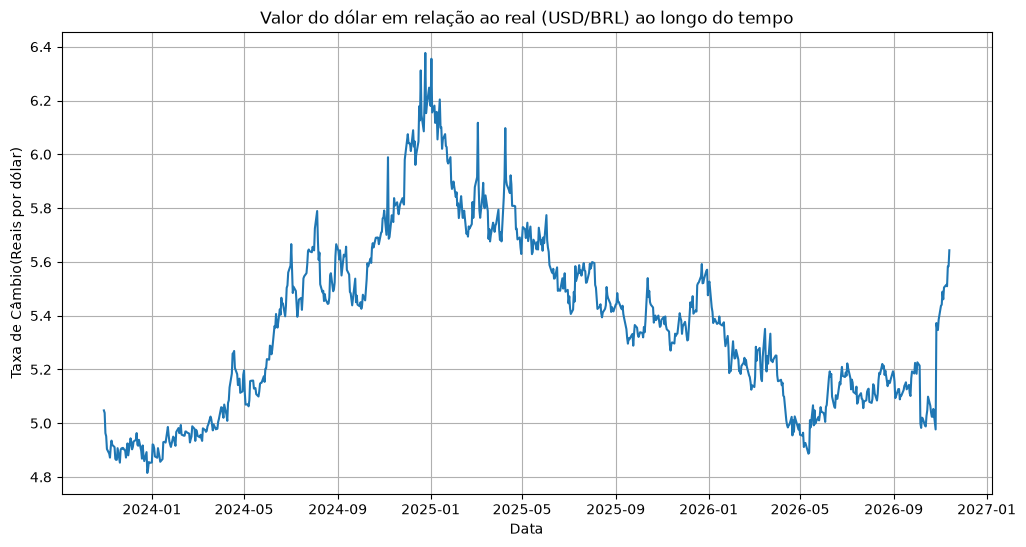

In [33]:
plt.figure(figsize=(12, 6))
plt.plot(cambio.index, cambio["USD_BRL"])
plt.title("Valor do dólar em relação ao real (USD/BRL) ao longo do tempo")
plt.xlabel("Data")
plt.ylabel("Taxa de Câmbio(Reais por dólar)")
plt.grid(True)
plt.show()

Manipulando dados para descobrir relação dólar euro 

In [34]:
cambio["USD_EUR"] = 1 / cambio["EUR_USD"]
series = cambio[["USD_BRL","USD_EUR"]]

base100 = series/series.iloc[0] * 100

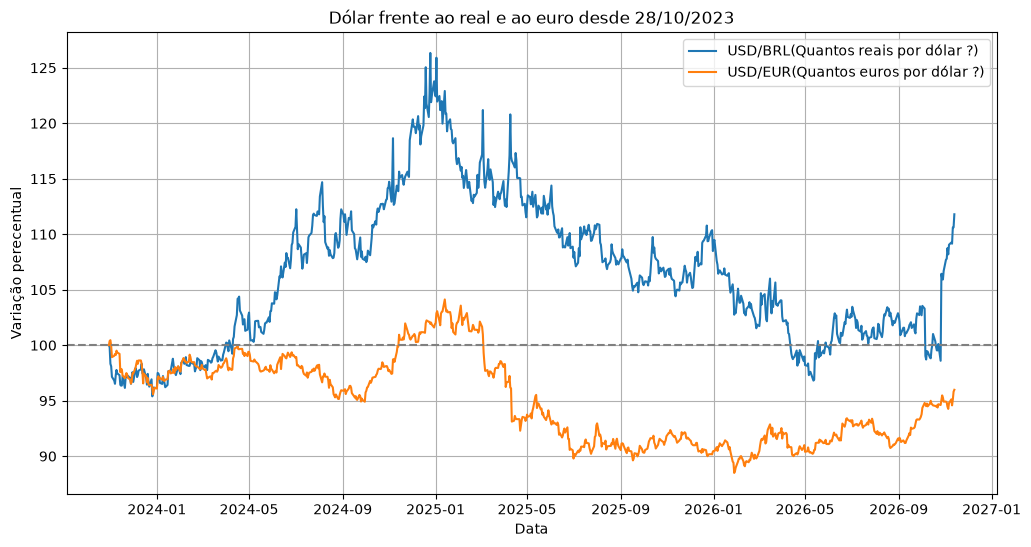

In [35]:
plt.figure(figsize=(12, 6))
plt.plot(base100["USD_BRL"], label="USD/BRL(Quantos reais por dólar ?)")
plt.plot(base100["USD_EUR"], label="USD/EUR(Quantos euros por dólar ?)")
plt.axhline(100, color="gray", linestyle="--")
plt.title("Dólar frente ao real e ao euro desde 28/10/2023")
plt.xlabel("Data")
plt.ylabel("Variação perecentual")
plt.legend()
plt.grid(True)
plt.show()

Decompondo a série temporal


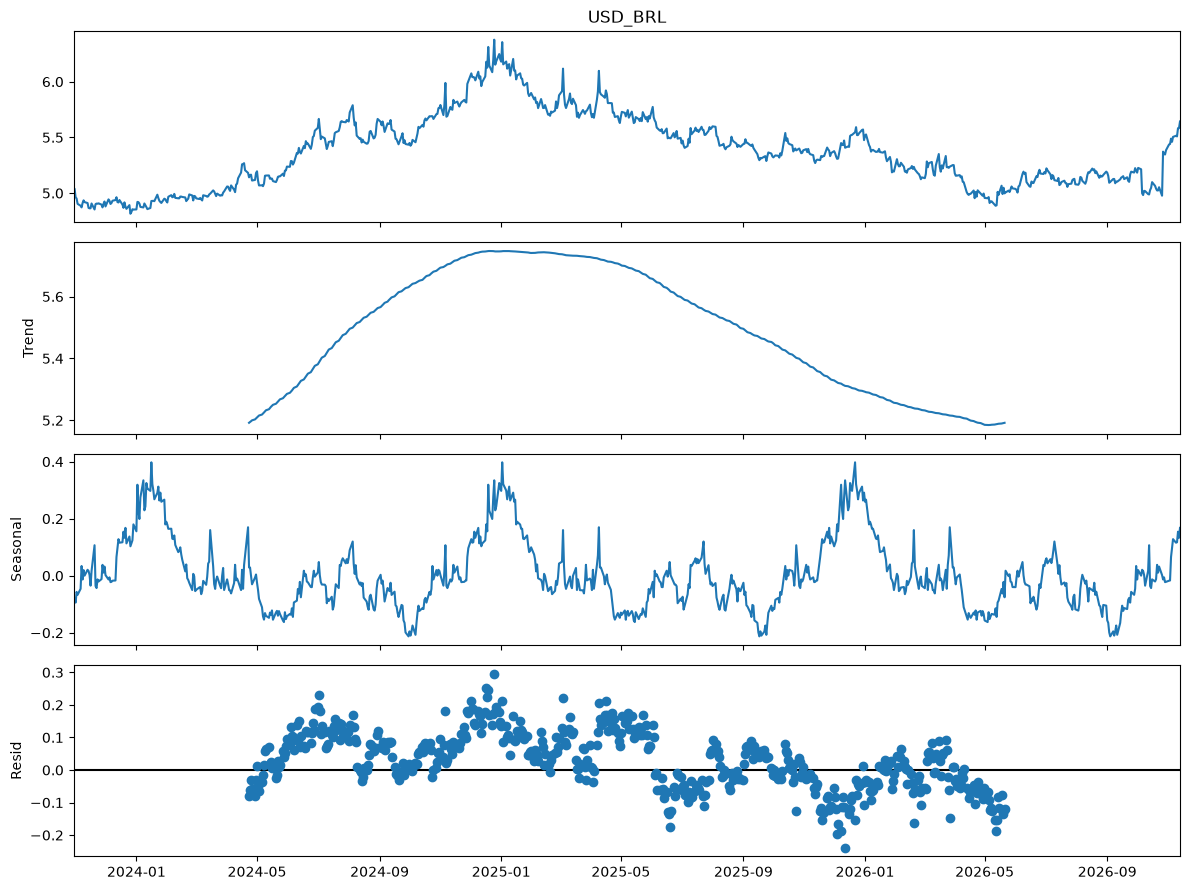

In [36]:
serie = cambio["USD_BRL"]
resultado = seasonal_decompose(serie, model="additive", period=252)

plt.rcParams["figure.figsize"] = (12, 9)
resultado.plot()
plt.show()

**1. A série possui tendência? Se sim, que tipo?**

Sim. A tendência extraída pela decomposição (média móvel de 252 dias úteis) é **não linear e muda de direção**: sobe até um máximo de R$ 5,75 (20/12/2024) e depois cai até R$ 5,18 (04/05/2026), uma queda de cerca de 10%. Tem formato de "morro", não de reta. A forte oscilação diária não elimina a tendência: ela fica por cima da direção de médio prazo.


**2. A série possui sazonalidade? Se sim, qual o período?**

**Pela análise do gráfico, sim.** O componente sazonal da decomposição mostra um padrão que se repete a cada ano (período de 252 dias úteis, ou 12 meses), com dólar mais alto em dezembro e janeiro (cerca de +R$ 0,20) e mais baixo em maio e setembro (cerca de −R$ 0,11).

**Análise adicional (além do pedido):** ao comparar cada mês com a média do próprio ano, o padrão não se repete de forma consistente (dezembro foi positivo em 2024 e negativo em 2025). Como a série tem só cerca de 3 anos, a sazonalidade anual é um indício e não pode ser confirmada.

In [37]:
s = cambio["USD_BRL"]
desvio = s - s.groupby(s.index.year).transform("mean")
print(desvio.groupby([desvio.index.year, desvio.index.month]).mean().unstack(0).round(2))

date  2023  2024  2025  2026
date                        
1      NaN -0.48  0.46  0.19
2      NaN -0.43  0.18  0.05
3      NaN -0.41  0.19  0.07
4      NaN -0.26  0.19 -0.12
5      NaN -0.25  0.08 -0.18
6      NaN -0.00 -0.04 -0.04
7      NaN  0.15 -0.08 -0.04
8      NaN  0.17 -0.14 -0.01
9      NaN  0.15 -0.23 -0.02
10    0.14  0.22 -0.21 -0.05
11   -0.00  0.42 -0.26  0.35
12   -0.01  0.73 -0.14   NaN


**3. A série apresenta um ciclo? Se sim, por qual razão?**

Sim. O resíduo da decomposição não é ruído: forma **ondas lentas de vários meses, sem período fixo** (positivo de mai/2024 a mai/2025, negativo de jun a dez/2025, positivo no início de 2026 e negativo de novo em abr/mai/2026). Como não se repetem em intervalo regular, são ciclos e não sazonalidade. Razões identificadas:
- **Fator global:** em 2025 o dólar também enfraqueceu frente ao euro, e o real se valorizou junto.
- **Fatores específicos do real:** em 26/10/2026 o dólar subiu 8,21% em um dia, após o resultado do segundo turno da eleição, enquanto o euro quase não se moveu.

Previsão de dados futuros com uso do modelo Arima

Preparando algoritmo para realizar as previsões

In [38]:
n_teste = 90
conjunto_treinamento = cambio["USD_BRL"].iloc[:-n_teste]
conjunto_teste = cambio["USD_BRL"].iloc[-n_teste:]

In [39]:

model = auto_arima(y=conjunto_treinamento,seasonal = False)

print(f"Melhor modelo ARIMA encontrado: {model.summary()}")

Melhor modelo ARIMA encontrado:                                SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  705
Model:               SARIMAX(0, 1, 2)   Log Likelihood                1127.699
Date:                Wed, 18 Nov 2026   AIC                          -2249.398
Time:                        00:44:21   BIC                          -2235.728
Sample:                    10-30-2023   HQIC                         -2244.115
                         - 07-10-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2451      0.022    -10.940      0.000      -0.289      -0.201
ma.L2         -0.0580      0.029     -2.022      0.043      -0.114      -0.002
sigma2         0.002

Previsões usando ARIMA

<Axes: xlabel='date'>

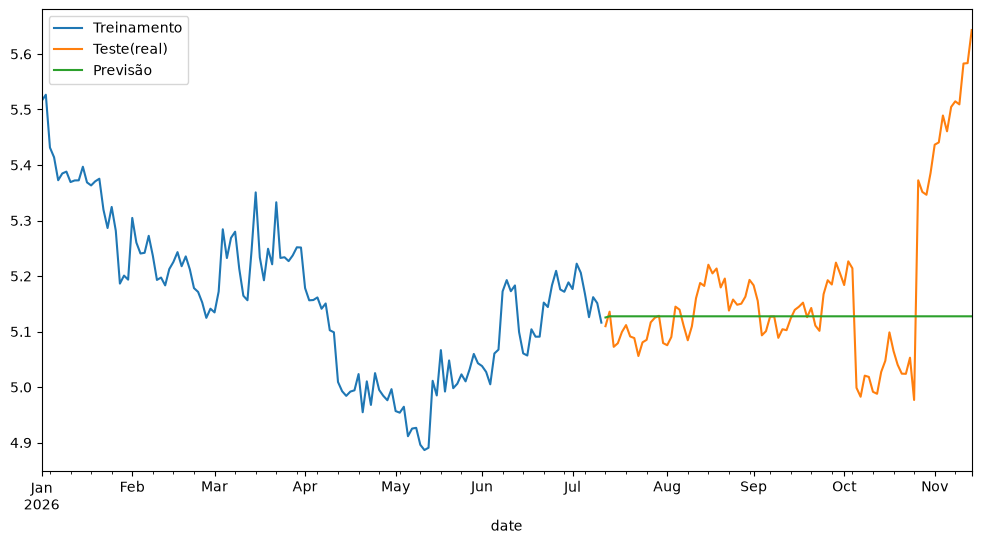

In [40]:
forecasting_arima = pd.Series (
    model.predict(n_periods=n_teste), index=conjunto_teste.index
)

conjunto_treinamento["2026-01-01":].plot(figsize=(12, 6), label="Treinamento", legend=True)

conjunto_teste.plot(label="Teste(real)", legend=True)
forecasting_arima.plot(label="Previsão", legend=True)

MAPE do ARIMA

In [41]:
def mape(real, previsto):
    return np.mean(np.abs((real.values - np.asarray(previsto)) / real.values)) * 100

print(f"MAPE ARIMA: {mape(conjunto_teste, forecasting_arima):.2f}%")

MAPE ARIMA: 1.82%


Previsão usando Holt-Winters

In [42]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


hw = ExponentialSmoothing(
    conjunto_treinamento, trend="add", seasonal="add", seasonal_periods=252
).fit()


prev_hw = pd.Series(hw.forecast(len(conjunto_teste)), index=conjunto_teste.index)

c:\Users\Gabriel\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


<Axes: xlabel='date'>

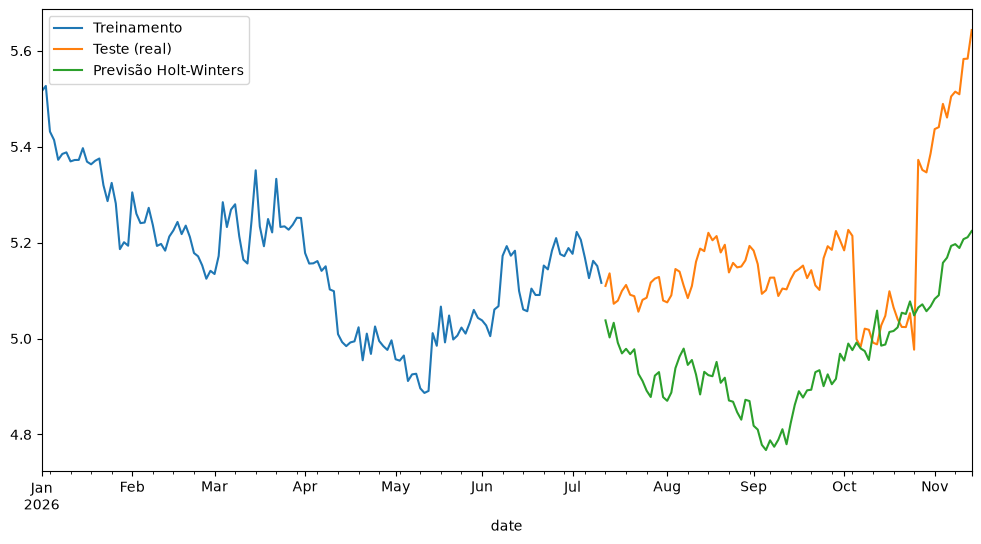

In [43]:
conjunto_treinamento["2026-01-01":].plot(figsize=(12, 6), label="Treinamento", legend=True)

conjunto_teste.plot(label="Teste (real)", legend=True)
prev_hw.plot(label="Previsão Holt-Winters", legend=True)

MAPE do Holt-Winters

In [44]:
print(f"MAPE Holt-Winters: {mape(conjunto_teste, prev_hw):.2f}%")

MAPE Holt-Winters: 4.17%


Juntando ambos os gráficos

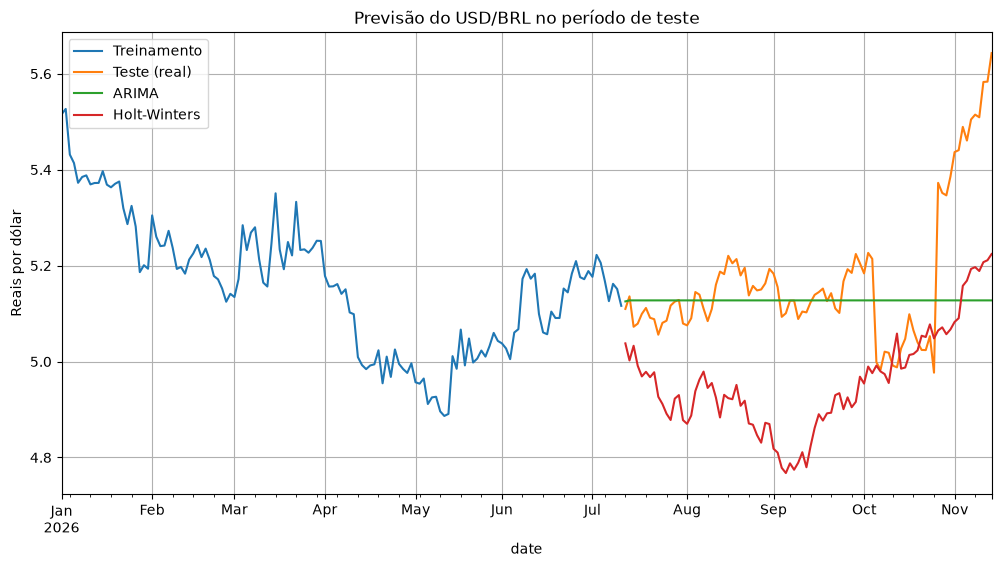

In [45]:
plt.figure(figsize=(12, 6))
conjunto_treinamento["2026-01-01":].plot(label="Treinamento", legend=True)
conjunto_teste.plot(label="Teste (real)", legend=True)
forecasting_arima.plot(label="ARIMA", legend=True)
prev_hw.plot(label="Holt-Winters", legend=True)
plt.title("Previsão do USD/BRL no período de teste")
plt.ylabel("Reais por dólar")
plt.grid(True)
plt.show()

Comparação MAPE

In [46]:
resultados = pd.DataFrame({
    "Modelo": ["ARIMA", "Holt-Winters"],
    "MAPE (%)": [
        mape(conjunto_teste, forecasting_arima),
        mape(conjunto_teste, prev_hw),
    ],
})
print(resultados.round(2))

         Modelo  MAPE (%)
0         ARIMA      1.82
1  Holt-Winters      4.17


Previsões finais

In [47]:
# ajustando o modelo com todos os dados
model_final = auto_arima(y=cambio["USD_BRL"], seasonal=False)
print(model_final)

# previsão para os próximos 30 dias úteis, com intervalo de confiança
n_futuro = 30
previsao, intervalo = model_final.predict(n_periods=n_futuro, return_conf_int=True)

datas_futuras = pd.bdate_range(start=cambio.index[-1] + pd.offsets.BDay(1), periods=n_futuro)
previsao_futura = pd.Series(previsao, index=datas_futuras)

print(previsao_futura.head())
print(previsao_futura.tail())

 ARIMA(0,1,1)(0,0,0)[0]          
2026-11-16    5.627836
2026-11-17    5.627836
2026-11-18    5.627836
2026-11-19    5.627836
2026-11-20    5.627836
Freq: B, dtype: float64
2026-12-21    5.627836
2026-12-22    5.627836
2026-12-23    5.627836
2026-12-24    5.627836
2026-12-25    5.627836
Freq: B, dtype: float64


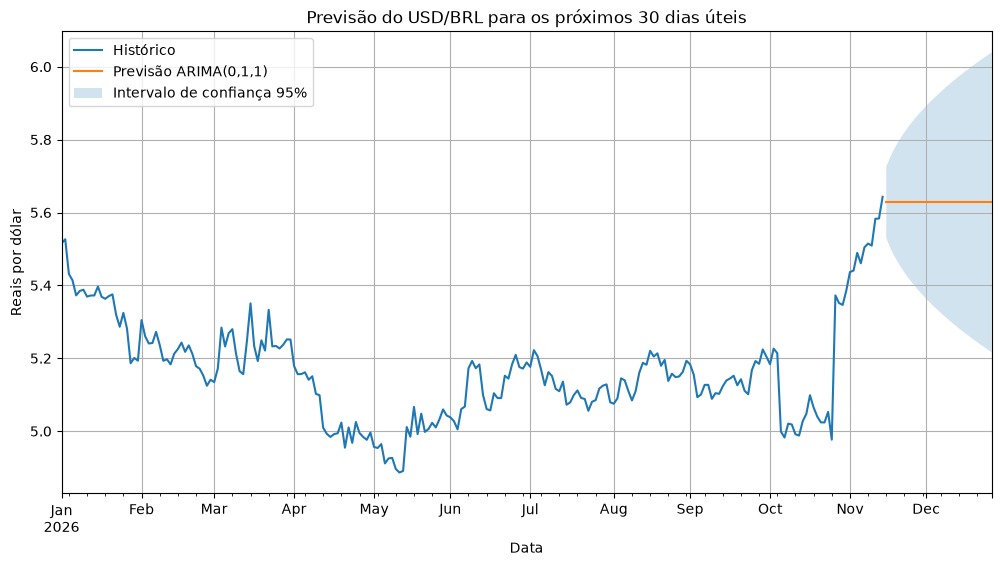

In [48]:

intervalo_df = pd.DataFrame(
    intervalo, index=datas_futuras, columns=["inferior", "superior"]
)

plt.figure(figsize=(12, 6))
cambio["USD_BRL"]["2026-01-01":].plot(label="Histórico", legend=True)
previsao_futura.plot(label="Previsão ARIMA(0,1,1)", legend=True)
plt.fill_between(
    datas_futuras,
    intervalo_df["inferior"],
    intervalo_df["superior"],
    alpha=0.2,
    label="Intervalo de confiança 95%",
)
plt.title("Previsão do USD/BRL para os próximos 30 dias úteis")
plt.xlabel("Data")
plt.ylabel("Reais por dólar")
plt.legend()
plt.grid(True)
plt.show()

Conclusões de qual modelo é melhor

**Método mais adequado para prever o USD/BRL**

No teste com os últimos 90 dias úteis (13/07 a 13/11/2026), o ARIMA obteve MAPE de 1,82% e o Holt-Winters, de 4,17%. O Holt-Winters previu uma queda forte em agosto e setembro, seguindo o padrão sazonal estimado, que não se repetiu em 2026, enquanto o ARIMA ficou na faixa em que o dólar de fato oscilou até o salto de 26/10/2026 (reação do mercado ao resultado da eleição), imprevisível para qualquer modelo. Em janelas de teste mais curtas (20 a 60 dias), que terminam nesse salto, o Holt-Winters chegou a ter menor erro, mas esse resultado depende de um evento isolado. Por ser mais estável e não depender de uma sazonalidade que não se confirmou ano a ano, o ARIMA é o método mais adequado para esta série.

**Previsão futura (ARIMA(0,1,1), 30 dias úteis a partir de 16/11/2026):** valor central constante de cerca de R$ 5,63, com intervalo de 95% entre R$ 5,22 e R$ 6,04 no último dia. A previsão reta e a faixa que se abre mostram que, para o câmbio, o histórico sozinho permite estimar a faixa de variação, mas não a direção.